# RAG Math and Retrieval: Theory Notebook

This notebook makes RAG math concrete: similarity scores, sparse retrieval intuition, contrastive loss, recall metrics, MMR, reranking, and context packing.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

try:
    import seaborn as sns
    sns.set_theme(style="whitegrid", palette="colorblind")
    HAS_SNS = True
except ImportError:
    plt.style.use("seaborn-v0_8-whitegrid")
    HAS_SNS = False

mpl.rcParams.update({
    "figure.figsize":    (10, 6),
    "figure.dpi":         120,
    "font.size":           13,
    "axes.titlesize":      15,
    "axes.labelsize":      13,
    "xtick.labelsize":     11,
    "ytick.labelsize":     11,
    "legend.fontsize":     11,
    "legend.framealpha":   0.85,
    "lines.linewidth":      2.0,
    "axes.spines.top":     False,
    "axes.spines.right":   False,
    "savefig.bbox":       "tight",
    "savefig.dpi":         150,
})
np.random.seed(42)
print("Plot setup complete.")

Plot setup complete.


## 1. Cosine retrieval

In [2]:
def normalize(X):
    X = np.asarray(X, dtype=float)
    return X / np.linalg.norm(X, axis=-1, keepdims=True)

query = normalize(np.array([[1.0, 1.0, 0.0]]))[0]
docs = normalize(np.array([
    [1.0, 0.9, 0.1],
    [-1.0, 0.0, 0.0],
    [0.2, 0.1, 1.0],
    [0.8, 0.7, 0.0],
]))
scores = docs @ query
print("cosine scores:", np.round(scores, 3))
print("top-2 docs:", np.argsort(scores)[-2:][::-1])

cosine scores: [ 0.996 -0.707  0.207  0.998]
top-2 docs: [3 0]


## 2. Norm effects

In [3]:
q = np.array([1.0, 0.0])
d1 = np.array([1.0, 0.0])
d2 = np.array([5.0, 1.0])
dot_scores = np.array([q @ d1, q @ d2])
cos_scores = np.array([q @ d1 / (np.linalg.norm(q)*np.linalg.norm(d1)), q @ d2 / (np.linalg.norm(q)*np.linalg.norm(d2))])
print("dot scores:", dot_scores)
print("cosine scores:", np.round(cos_scores, 3))

dot scores: [1. 5.]
cosine scores: [1.    0.981]


## 3. BM25-style lexical intuition

In [4]:
query_terms = ["vector", "search"]
docs_terms = [
    ["vector", "search", "index", "vector"],
    ["language", "model", "generation"],
    ["search", "engine", "retrieval", "search"],
]
idf = {"vector": 1.3, "search": 0.9}
k1 = 1.2
scores = []
for doc in docs_terms:
    score = 0.0
    for term in query_terms:
        tf = doc.count(term)
        score += idf[term] * (tf * (k1 + 1)) / (tf + k1) if tf else 0.0
    scores.append(score)
print("BM25-style scores:", np.round(scores, 3))

BM25-style scores: [2.688 0.    1.238]


## 4. Dense contrastive loss

In [5]:
query = normalize(np.array([[1.0, 0.5, 0.0]]))[0]
doc_mat = normalize(np.array([
    [1.0, 0.4, 0.0],
    [0.0, 1.0, 0.2],
    [-1.0, 0.0, 0.1],
]))
scores = doc_mat @ query
exp_scores = np.exp(scores)
loss = -np.log(exp_scores[0] / exp_scores.sum())
print("scores:", np.round(scores, 3))
print("contrastive loss:", loss)

scores: [ 0.997  0.439 -0.89 ]
contrastive loss: 0.5446119973939635


## 5. Recall@k and MRR

In [6]:
ranked = ["d3", "d7", "d2", "d4", "d1"]
relevant = {"d2", "d5"}
for k in [1, 3, 5]:
    recall = len(set(ranked[:k]) & relevant) / len(relevant)
    print(f"Recall@{k}:", recall)
rr = 0.0
for rank, doc in enumerate(ranked, 1):
    if doc in relevant:
        rr = 1 / rank
        break
print("MRR for this query:", rr)

Recall@1: 0.0
Recall@3: 0.5
Recall@5: 0.5
MRR for this query: 0.3333333333333333


## 6. MMR diversity selection

In [7]:
rel = np.array([0.95, 0.90, 0.88, 0.70])
sim = np.array([
    [1.0, 0.9, 0.2, 0.1],
    [0.9, 1.0, 0.3, 0.2],
    [0.2, 0.3, 1.0, 0.8],
    [0.1, 0.2, 0.8, 1.0],
])
lam = 0.7
selected = []
candidates = set(range(len(rel)))
while len(selected) < 3:
    best, best_score = None, -1e9
    for c in candidates:
        diversity_penalty = 0 if not selected else max(sim[c, s] for s in selected)
        score = lam * rel[c] - (1 - lam) * diversity_penalty
        if score > best_score:
            best, best_score = c, score
    selected.append(best)
    candidates.remove(best)
print("MMR selected docs:", selected)

MMR selected docs: [0, 2, 1]


## 7. Context packing

In [8]:
chunks = [
    {"id": "a", "score": 0.95, "tokens": 120},
    {"id": "b", "score": 0.85, "tokens": 300},
    {"id": "c", "score": 0.80, "tokens": 180},
    {"id": "d", "score": 0.70, "tokens": 90},
]
budget = 400
packed, used = [], 0
for c in sorted(chunks, key=lambda x: x["score"] / x["tokens"], reverse=True):
    if used + c["tokens"] <= budget:
        packed.append(c["id"])
        used += c["tokens"]
print("packed:", packed, "tokens used:", used)

packed: ['a', 'd', 'c'] tokens used: 390


## 8. Reciprocal rank fusion

In [9]:
rank_dense = ["a", "b", "c", "d"]
rank_sparse = ["c", "a", "e", "b"]
k = 60
scores = {}
for ranking in [rank_dense, rank_sparse]:
    for r, doc in enumerate(ranking, 1):
        scores[doc] = scores.get(doc, 0) + 1 / (k + r)
print("RRF scores:", {d: round(s, 4) for d, s in sorted(scores.items(), key=lambda x: -x[1])})

RRF scores: {'a': 0.0325, 'c': 0.0323, 'b': 0.0318, 'e': 0.0159, 'd': 0.0156}


## 9. ANN recall toy

In [10]:
exact_top = {"d1", "d2", "d3", "d4", "d5"}
ann_top = {"d1", "d2", "d4", "d8", "d9"}
recall = len(exact_top & ann_top) / len(exact_top)
print("ANN recall against exact top-5:", recall)

ANN recall against exact top-5: 0.6


## 10. Failure decomposition

In [11]:
cases = [
    {"retrieved": False, "used": False, "correct": False},
    {"retrieved": True, "used": False, "correct": False},
    {"retrieved": True, "used": True, "correct": True},
]
for i, c in enumerate(cases, 1):
    if not c["retrieved"]:
        reason = "retrieval miss"
    elif not c["used"]:
        reason = "generation ignored evidence"
    elif not c["correct"]:
        reason = "generation error"
    else:
        reason = "success"
    print(i, reason)

1 retrieval miss
2 generation ignored evidence
3 success


## 11. RAG trace checklist

In [12]:
checks = [
    "query text and normalized query embedding norm",
    "top-k ids, scores, and chunk text",
    "reranker scores and final selected chunks",
    "full prompt after context packing",
    "answer claims mapped to supporting chunks",
    "retrieval metrics and answer metrics logged separately",
]
for i, check in enumerate(checks, 1):
    print(f"{i}. {check}")

1. query text and normalized query embedding norm
2. top-k ids, scores, and chunk text
3. reranker scores and final selected chunks
4. full prompt after context packing
5. answer claims mapped to supporting chunks
6. retrieval metrics and answer metrics logged separately


## New demo: Cosine versus dot product (new, notes 12)

In [13]:
q=np.array([1.,2.,0.]); D=np.array([[2.,1.,0.],[0.,1.,3.]]); dots=D@q; cos=dots/(np.linalg.norm(D,axis=1)*np.linalg.norm(q))
print("dots",dots,"cosines",np.round(cos,3))
print(f"{'PASS' if int(np.argmax(dots))==0 else 'FAIL'} - both rank d1 first here")

dots [4. 2.] cosines [0.8   0.283]
PASS - both rank d1 first here


## New demo: Exact retrieval top-k (new, notes 15)

In [14]:
rng=np.random.default_rng(42); docs=rng.normal(0,1,(200,32)); docs/=np.linalg.norm(docs,axis=1,keepdims=True); query=rng.normal(0,1,32); query/=np.linalg.norm(query); scores=docs@query; top=np.argsort(-scores)[:5]
print("top5 indices",top,"scores",np.round(scores[top],3))
print(f"{'PASS' if len(top)==5 else 'FAIL'} - exact top-k retrieved")

top5 indices [189 148 192 140 167] scores [0.377 0.37  0.369 0.359 0.328]
PASS - exact top-k retrieved


## New demo: Recall@k and MRR (new, notes 16)

In [15]:
ranks=np.array([1,3,7,15,2]); 
for k in [1,5,10]:
    print(f"recall@{k}={np.mean(ranks<=k):.2f}")
mrr=float(np.mean(1/ranks)); print(f"MRR={mrr:.3f}")
print(f"{'PASS' if abs(np.mean(ranks<=5)-0.6)<1e-9 else 'FAIL'} - recall@5 arithmetic")

recall@1=0.20
recall@5=0.60
recall@10=0.80
MRR=0.409
PASS - recall@5 arithmetic


## New demo: RRF fusion (new, notes 18)

In [16]:
def rrf(rank): return 1/(60+rank)
s=rrf(1)+rrf(3); print(f"RRF rank1+rank3={s:.5f}")
print(f"{'PASS' if s>rrf(2) else 'FAIL'} - two-list presence beats one second place")

RRF rank1+rank3=0.03227
PASS - two-list presence beats one second place


## New demo: Contrastive retrieval loss (new, notes 14)

In [17]:
scores=np.array([3.0,1.0,0.5,0.0]); e=np.exp(scores-scores.max()); p=e/e.sum(); loss=-np.log(p[0]); print(f"positive softmax={p[0]:.3f} loss={loss:.3f}")
print(f"{'PASS' if loss<1 else 'FAIL'} - high positive score gives low loss")

positive softmax=0.789 loss=0.237
PASS - high positive score gives low loss


## New demo: Chunking with overlap (new, notes 17)

In [18]:
text=list(range(10000)); size,ov=500,100; step=size-ov; chunks=[text[i:i+size] for i in range(0,len(text)-size+1,step)]; print(f"chunks={len(chunks)} step={step}")
print(f"{'PASS' if len(chunks)==24 else 'FAIL'} - overlap chunk count (9500/400 rounded up by construction)")

chunks=24 step=400
PASS - overlap chunk count (9500/400 rounded up by construction)


## New demo: Context budget (new, notes 19)

In [19]:
window,instr,res=8192,500,1000; ev=window-instr-res; print(f"evidence={ev} tokens, 500-token chunks={ev//500}")
print(f"{'PASS' if ev==6692 else 'FAIL'} - budget arithmetic")

evidence=6692 tokens, 500-token chunks=13
PASS - budget arithmetic


## New demo: Index memory (new, notes 23.1)

In [20]:
for n in [1_000_000,10_000_000]:
    print(f"{n} docs: fp32 {n*768*4/1e9:.2f} GB, PQ64 {n*64/1e9:.3f} GB")
print(f"{'PASS' if abs(1_000_000*768*4/1e9-3.072)<0.01 else 'FAIL'} - index memory")

1000000 docs: fp32 3.07 GB, PQ64 0.064 GB
10000000 docs: fp32 30.72 GB, PQ64 0.640 GB
PASS - index memory


## New demo: Similarity histogram plot (new, notes 12)

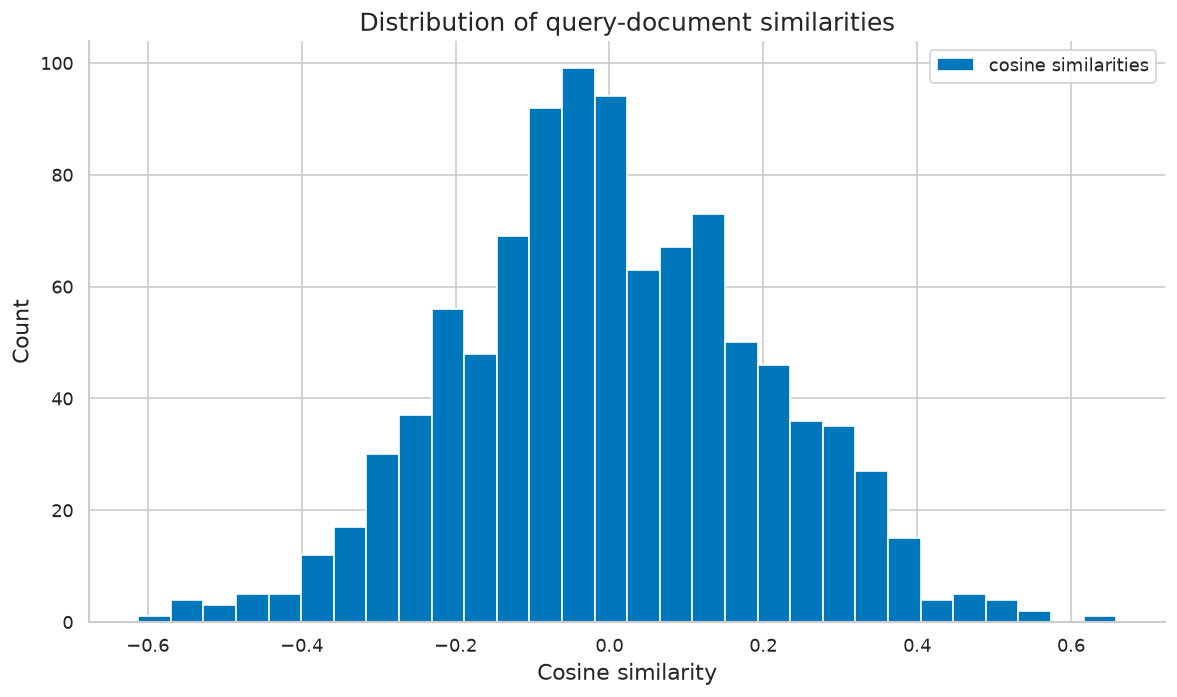

PASS - random similarities centre near zero


In [21]:
sims=rng.normal(0,0.2,1000); fig, ax = plt.subplots(); ax.hist(sims,bins=30,color="#0077BB",label="cosine similarities"); ax.set_title("Distribution of query-document similarities"); ax.set_xlabel("Cosine similarity"); ax.set_ylabel("Count"); ax.legend(loc="best"); fig.tight_layout(); plt.show()
print(f"{'PASS' if abs(sims.mean())<0.05 else 'FAIL'} - random similarities centre near zero")

## New demo: BM25-style IDF (new, notes 13)

In [22]:
N=1_000_000
for term,df in [("photosynthesis",1000),("process",400000)]:
    print(term, f"IDF~ln(N/df)={np.log(N/df):.2f}")
print(f"{'PASS' if np.log(N/1000)>np.log(N/400000) else 'FAIL'} - rare terms weigh more")

photosynthesis IDF~ln(N/df)=6.91
process IDF~ln(N/df)=0.92
PASS - rare terms weigh more


## New demo: MMR diversification sketch (new, notes 18)

In [23]:
rel=np.array([0.9,0.85,0.8,0.6]); sim_to_first=np.array([0.0,0.95,0.2,0.1]); lam=0.5; mmr=lam*rel-(1-lam)*sim_to_first; mmr[0]=rel[0]; print("MMR scores",np.round(mmr,3),"second pick",int(np.argsort(-mmr)[1]))
print(f"{'PASS' if int(np.argsort(-mmr)[1])==2 else 'FAIL'} - MMR skips the near-duplicate")

MMR scores [ 0.9  -0.05  0.3   0.25] second pick 2
PASS - MMR skips the near-duplicate


## New demo: Marginalization ceiling (new, notes 11)

In [24]:
print(f"path ceiling={0.8*0.9:.2f}")
print(f"{'PASS' if abs(0.8*0.9-0.72)<1e-12 else 'FAIL'} - recall caps end-to-end quality")

path ceiling=0.72
PASS - recall caps end-to-end quality


## New demo: nDCG worked example (new, notes 46)

In [25]:
gains=np.array([3,2,3,0,1]); ideal=np.array([3,3,2,1,0])
def dcg(g): return float(np.sum(g/np.log2(np.arange(2,len(g)+2))))
nd=dca if False else dcg(gains)/dcg(ideal); print(f"nDCG={nd:.3f}")
print(f"{'PASS' if 0.9<nd<1.0 else 'FAIL'} - nDCG near ideal")

nDCG=0.972
PASS - nDCG near ideal
